In [64]:
# ==========================================================
# 1. IMPORT LIBRARIES
# ==========================================================

import os
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")


Libraries imported successfully.


In [65]:
# ==========================================================
# 2. DATASET PATH
# ==========================================================

base_path = r"C:\Users\kvspp\Downloads\aiml project\CMAPSSData"

train_path = base_path + r"\train_FD001.txt"
test_path = base_path + r"\test_FD001.txt"
rul_path = base_path + r"\RUL_FD001.txt"

print("Base path:")
print(base_path)

print("\nChecking files:")

for file_path in [train_path, test_path, rul_path]:
    print(file_path, "->", os.path.exists(file_path))

if not all(os.path.exists(x) for x in [train_path, test_path, rul_path]):
    raise FileNotFoundError(
        "One or more FD001 files were not found. "
        "Check the base_path."
    )


Base path:
C:\Users\kvspp\Downloads\aiml project\CMAPSSData

Checking files:
C:\Users\kvspp\Downloads\aiml project\CMAPSSData\train_FD001.txt -> True
C:\Users\kvspp\Downloads\aiml project\CMAPSSData\test_FD001.txt -> True
C:\Users\kvspp\Downloads\aiml project\CMAPSSData\RUL_FD001.txt -> True


In [66]:
# ==========================================================
# 3. C-MAPSS COLUMN NAMES
# ==========================================================

columns = [
    "Unit",
    "Cycle",
    "Operational_Setting_1",
    "Operational_Setting_2",
    "Operational_Setting_3",
    "Sensor_1",
    "Sensor_2",
    "Sensor_3",
    "Sensor_4",
    "Sensor_5",
    "Sensor_6",
    "Sensor_7",
    "Sensor_8",
    "Sensor_9",
    "Sensor_10",
    "Sensor_11",
    "Sensor_12",
    "Sensor_13",
    "Sensor_14",
    "Sensor_15",
    "Sensor_16",
    "Sensor_17",
    "Sensor_18",
    "Sensor_19",
    "Sensor_20",
    "Sensor_21"
]

print("Number of columns:", len(columns))


Number of columns: 26


In [67]:
# ==========================================================
# 4. LOAD DATA
# ==========================================================

train_df = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    test_path,
    sep=r"\s+",
    header=None,
    names=columns
)

rul_df = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Data loaded successfully.")


Data loaded successfully.


In [68]:
# ==========================================================
# 5. CALCULATE TRAINING RUL AND TESTING RUL
# ==========================================================

# ----------------------------------------------------------
# TRAINING RUL
# ----------------------------------------------------------

train_df["RUL"] = (
    train_df.groupby("Unit")["Cycle"].transform("max")
    - train_df["Cycle"]
)

# ----------------------------------------------------------
# TESTING RUL
# ----------------------------------------------------------

# Find the last observed cycle for every test engine
test_max_cycle = (
    test_df.groupby("Unit")["Cycle"]
    .max()
)

# IMPORTANT:
# RUL_FD001 contains one RUL value for each test engine.
# The first value belongs to Unit 1, second to Unit 2, etc.

rul_df["Unit"] = np.arange(
    1,
    len(rul_df) + 1
)

# Create a proper Unit -> RUL mapping
rul_lookup = rul_df.set_index("Unit")["RUL"]

# Calculate RUL for every test observation
test_df["RUL"] = (
    test_df["Unit"].map(rul_lookup)
    + test_df["Unit"].map(test_max_cycle)
    - test_df["Cycle"]
)

# ----------------------------------------------------------
# CHECK FOR PROBLEMS
# ----------------------------------------------------------

print("=" * 70)
print("RUL CALCULATION CHECK")
print("=" * 70)

print("\nTraining RUL missing values:",
      train_df["RUL"].isna().sum())

print("Testing RUL missing values:",
      test_df["RUL"].isna().sum())

print("\nTraining RUL range:")
print(
    train_df["RUL"].min(),
    "to",
    train_df["RUL"].max()
)

print("\nTesting RUL range:")
print(
    test_df["RUL"].min(),
    "to",
    test_df["RUL"].max()
)

print("\nRUL calculation completed successfully.")

RUL CALCULATION CHECK

Training RUL missing values: 0
Testing RUL missing values: 0

Training RUL range:
0 to 361

Testing RUL range:
7 to 340

RUL calculation completed successfully.


In [69]:
# ==========================================================
# 6. BASIC DATA INSPECTION
# ==========================================================

print("=" * 70)
print("NASA C-MAPSS FD001 DATASET")
print("=" * 70)

print("\nTRAINING DATA")
print(train_df.head())

print("\nTESTING DATA")
print(test_df.head())

print("\nRUL DATA")
print(rul_df.head())

print("\nTRAINING SHAPE:", train_df.shape)
print("TESTING SHAPE :", test_df.shape)
print("RUL SHAPE     :", rul_df.shape)

print("\nTRAINING ENGINES:", train_df["Unit"].nunique())
print("TESTING ENGINES :", test_df["Unit"].nunique())

print("\nDATA TYPES")
print(train_df.dtypes)


NASA C-MAPSS FD001 DATASET

TRAINING DATA
   Unit  Cycle  Operational_Setting_1  Operational_Setting_2  \
0     1      1                -0.0007                -0.0004   
1     1      2                 0.0019                -0.0003   
2     1      3                -0.0043                 0.0003   
3     1      4                 0.0007                 0.0000   
4     1      5                -0.0019                -0.0002   

   Operational_Setting_3  Sensor_1  Sensor_2  Sensor_3  Sensor_4  Sensor_5  \
0                  100.0    518.67    641.82   1589.70   1400.60     14.62   
1                  100.0    518.67    642.15   1591.82   1403.14     14.62   
2                  100.0    518.67    642.35   1587.99   1404.20     14.62   
3                  100.0    518.67    642.35   1582.79   1401.87     14.62   
4                  100.0    518.67    642.37   1582.85   1406.22     14.62   

   ...  Sensor_13  Sensor_14  Sensor_15  Sensor_16  Sensor_17  Sensor_18  \
0  ...    2388.02    8138.62

In [70]:
# ==========================================================
# 7. MISSING VALUES AND BASIC STATISTICS
# ==========================================================

print("=" * 70)
print("MISSING VALUES")
print("=" * 70)

print(train_df.isnull().sum().sum(), "missing values in training data")
print(test_df.isnull().sum().sum(), "missing values in testing data")

print("\nTRAINING STATISTICS")
print(train_df.describe().T)

print("\nRUL RANGE")
print("Minimum RUL:", train_df["RUL"].min())
print("Maximum RUL:", train_df["RUL"].max())


MISSING VALUES
0 missing values in training data
0 missing values in testing data

TRAINING STATISTICS
                         count         mean           std        min  \
Unit                   20631.0    51.506568  2.922763e+01     1.0000   
Cycle                  20631.0   108.807862  6.888099e+01     1.0000   
Operational_Setting_1  20631.0    -0.000009  2.187313e-03    -0.0087   
Operational_Setting_2  20631.0     0.000002  2.930621e-04    -0.0006   
Operational_Setting_3  20631.0   100.000000  0.000000e+00   100.0000   
Sensor_1               20631.0   518.670000  0.000000e+00   518.6700   
Sensor_2               20631.0   642.680934  5.000533e-01   641.2100   
Sensor_3               20631.0  1590.523119  6.131150e+00  1571.0400   
Sensor_4               20631.0  1408.933782  9.000605e+00  1382.2500   
Sensor_5               20631.0    14.620000  5.329200e-15    14.6200   
Sensor_6               20631.0    21.609803  1.388985e-03    21.6000   
Sensor_7               20631.0   

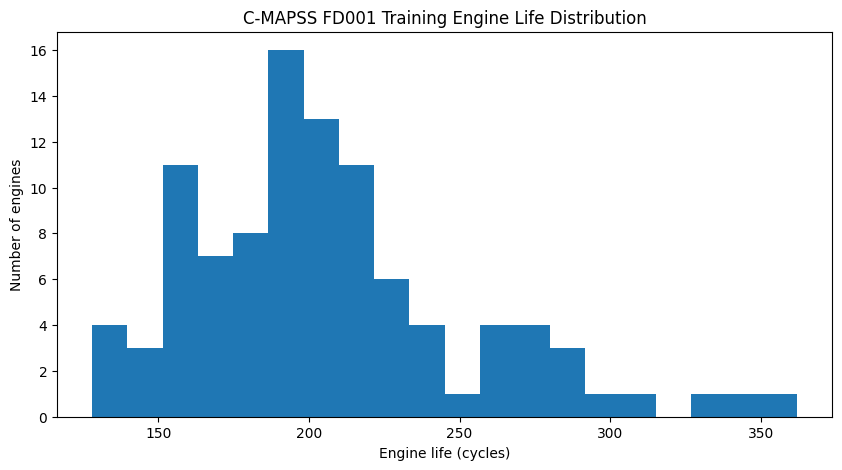

In [71]:
# ==========================================================
# 8. ENGINE LIFE DISTRIBUTION
# ==========================================================

engine_life = train_df.groupby("Unit")["Cycle"].max()

plt.figure(figsize=(10, 5))
plt.hist(engine_life, bins=20)
plt.xlabel("Engine life (cycles)")
plt.ylabel("Number of engines")
plt.title("C-MAPSS FD001 Training Engine Life Distribution")
plt.show()


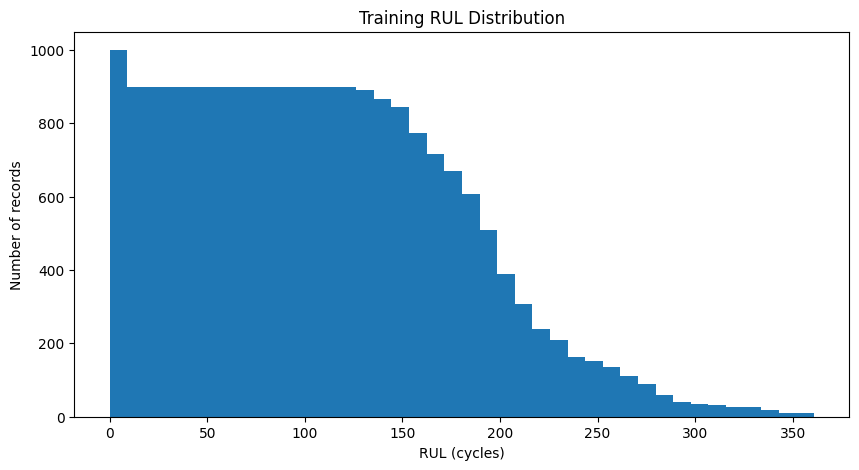

In [72]:
# ==========================================================
# 9. RUL DISTRIBUTION
# ==========================================================

plt.figure(figsize=(10, 5))
plt.hist(train_df["RUL"], bins=40)
plt.xlabel("RUL (cycles)")
plt.ylabel("Number of records")
plt.title("Training RUL Distribution")
plt.show()


Correlation with RUL:
Cycle                   -0.736241
Sensor_11               -0.696228
Sensor_4                -0.678948
Sensor_15               -0.642667
Sensor_2                -0.606484
Sensor_17               -0.606154
Sensor_3                -0.584520
Sensor_8                -0.563968
Sensor_13               -0.562569
Sensor_9                -0.390102
Sensor_14               -0.306769
Sensor_6                -0.128348
Operational_Setting_1   -0.003198
Operational_Setting_2   -0.001948
Unit                     0.078753
Sensor_20                0.629428
Sensor_21                0.635662
Sensor_7                 0.657223
Sensor_12                0.671983
Operational_Setting_3         NaN
Sensor_1                      NaN
Sensor_5                      NaN
Sensor_10                     NaN
Sensor_16                     NaN
Sensor_18                     NaN
Sensor_19                     NaN
Name: RUL, dtype: float64


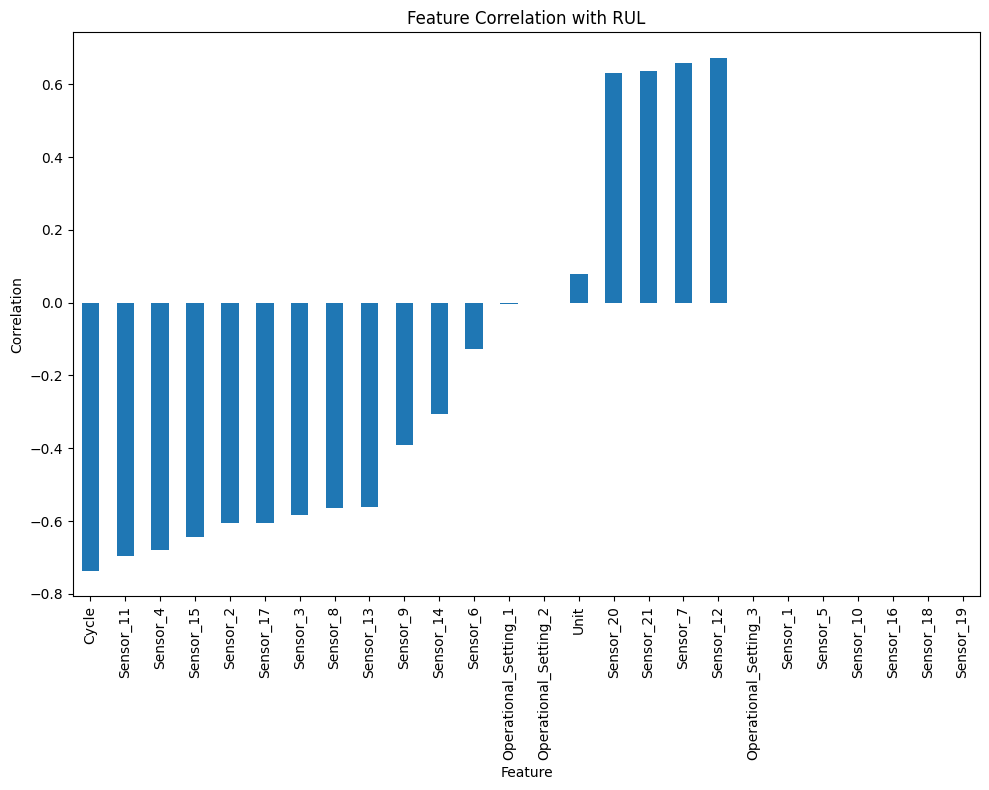

In [73]:
# ==========================================================
# 10. CORRELATION WITH RUL
# ==========================================================

numeric_columns = train_df.select_dtypes(include=np.number).columns

rul_correlation = (
    train_df[numeric_columns]
    .corr()["RUL"]
    .drop("RUL")
    .sort_values()
)

print("Correlation with RUL:")
print(rul_correlation)

plt.figure(figsize=(10, 8))
rul_correlation.plot(kind="bar")
plt.title("Feature Correlation with RUL")
plt.xlabel("Feature")
plt.ylabel("Correlation")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [74]:
# ==========================================================
# 11. ENGINE-LEVEL TRAIN / VALIDATION SPLIT
# ==========================================================

# Split by engine instead of by row.
# This avoids having the same engine trajectory in both sets.

engine_ids = train_df["Unit"].unique()

train_units, validation_units = train_test_split(
    engine_ids,
    test_size=0.20,
    random_state=42
)

model_train_df = train_df[
    train_df["Unit"].isin(train_units)
].copy()

validation_df = train_df[
    train_df["Unit"].isin(validation_units)
].copy()

print("Training engines:", len(train_units))
print("Validation engines:", len(validation_units))

print("Training rows:", model_train_df.shape)
print("Validation rows:", validation_df.shape)


Training engines: 80
Validation engines: 20
Training rows: (16561, 27)
Validation rows: (4070, 27)


In [75]:
# ==========================================================
# 12. PREPARE FEATURES
# ==========================================================

# Unit is an identifier, so it is not used as a feature.
# RUL is the target.

feature_columns = [
    column for column in columns
    if column not in ["Unit"]
]

X_train = model_train_df[feature_columns]
y_train = model_train_df["RUL"]

X_validation = validation_df[feature_columns]
y_validation = validation_df["RUL"]

print("Number of features:", len(feature_columns))
print(feature_columns)


Number of features: 25
['Cycle', 'Operational_Setting_1', 'Operational_Setting_2', 'Operational_Setting_3', 'Sensor_1', 'Sensor_2', 'Sensor_3', 'Sensor_4', 'Sensor_5', 'Sensor_6', 'Sensor_7', 'Sensor_8', 'Sensor_9', 'Sensor_10', 'Sensor_11', 'Sensor_12', 'Sensor_13', 'Sensor_14', 'Sensor_15', 'Sensor_16', 'Sensor_17', 'Sensor_18', 'Sensor_19', 'Sensor_20', 'Sensor_21']


In [76]:
# ==========================================================
# 13. XGBOOST RUL MODEL
# ==========================================================

xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost RUL model trained successfully.")


XGBoost RUL model trained successfully.


In [77]:
# ==========================================================
# 14. VALIDATION PREDICTION
# ==========================================================

validation_pred = xgb_model.predict(X_validation)

validation_results = validation_df[
    ["Unit", "Cycle", "RUL"]
].copy()

validation_results["Predicted_RUL"] = validation_pred

print(validation_results.head())


   Unit  Cycle  RUL  Predicted_RUL
0     1      1  191     215.410370
1     1      2  190     216.739975
2     1      3  189     221.429398
3     1      4  188     221.301437
4     1      5  187     220.647964


In [78]:
# ==========================================================
# 15. RUL MODEL EVALUATION
# ==========================================================

mae = mean_absolute_error(
    validation_results["RUL"],
    validation_results["Predicted_RUL"]
)

rmse = np.sqrt(
    mean_squared_error(
        validation_results["RUL"],
        validation_results["Predicted_RUL"]
    )
)

r2 = r2_score(
    validation_results["RUL"],
    validation_results["Predicted_RUL"]
)

print("=" * 70)
print("RUL MODEL PERFORMANCE")
print("=" * 70)

print("MAE :", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2  :", round(r2, 3))


RUL MODEL PERFORMANCE
MAE : 23.474
RMSE: 30.935
R2  : 0.778


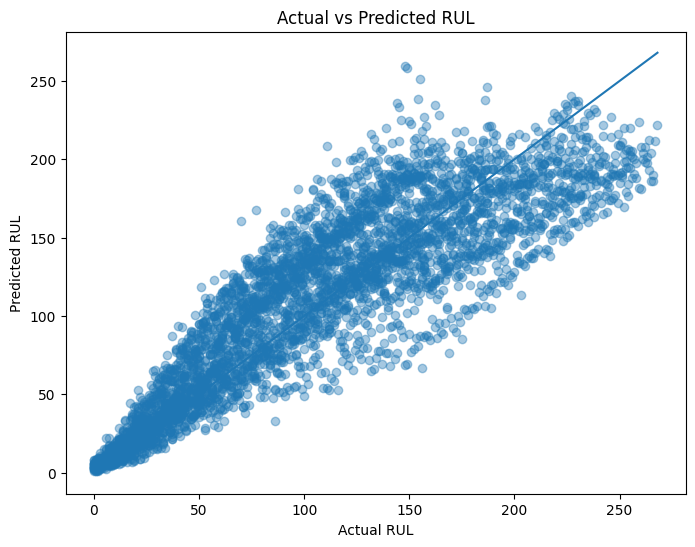

In [79]:
# ==========================================================
# 16. ACTUAL VS PREDICTED RUL
# ==========================================================

plt.figure(figsize=(8, 6))
plt.scatter(
    validation_results["RUL"],
    validation_results["Predicted_RUL"],
    alpha=0.4
)

minimum_value = min(
    validation_results["RUL"].min(),
    validation_results["Predicted_RUL"].min()
)

maximum_value = max(
    validation_results["RUL"].max(),
    validation_results["Predicted_RUL"].max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value]
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")
plt.show()


SHAP version: 0.52.0


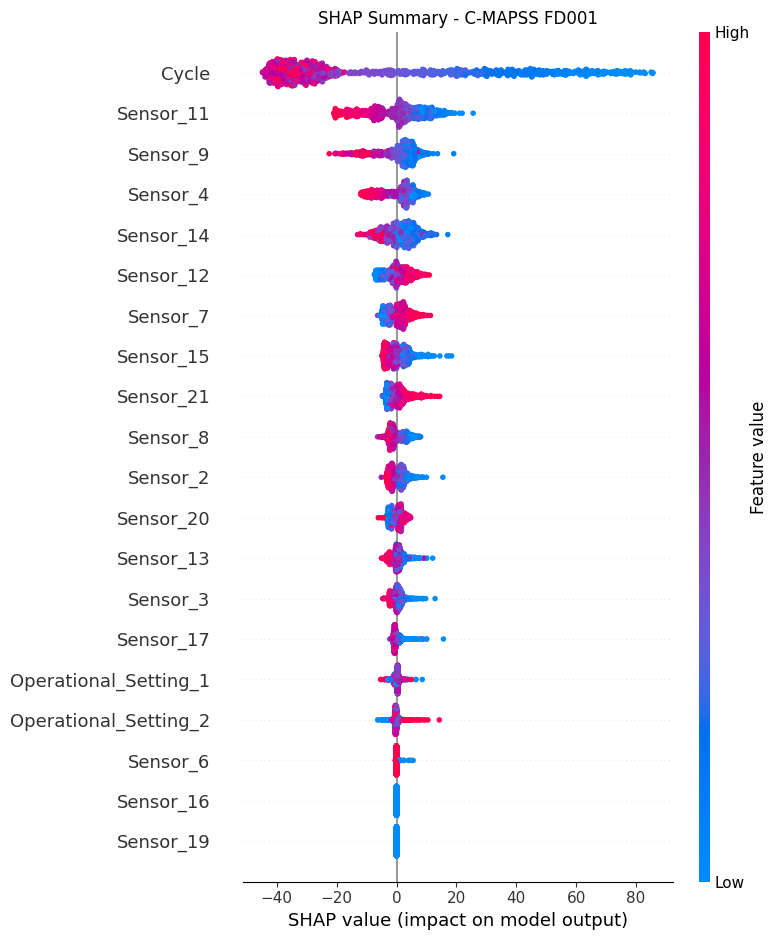

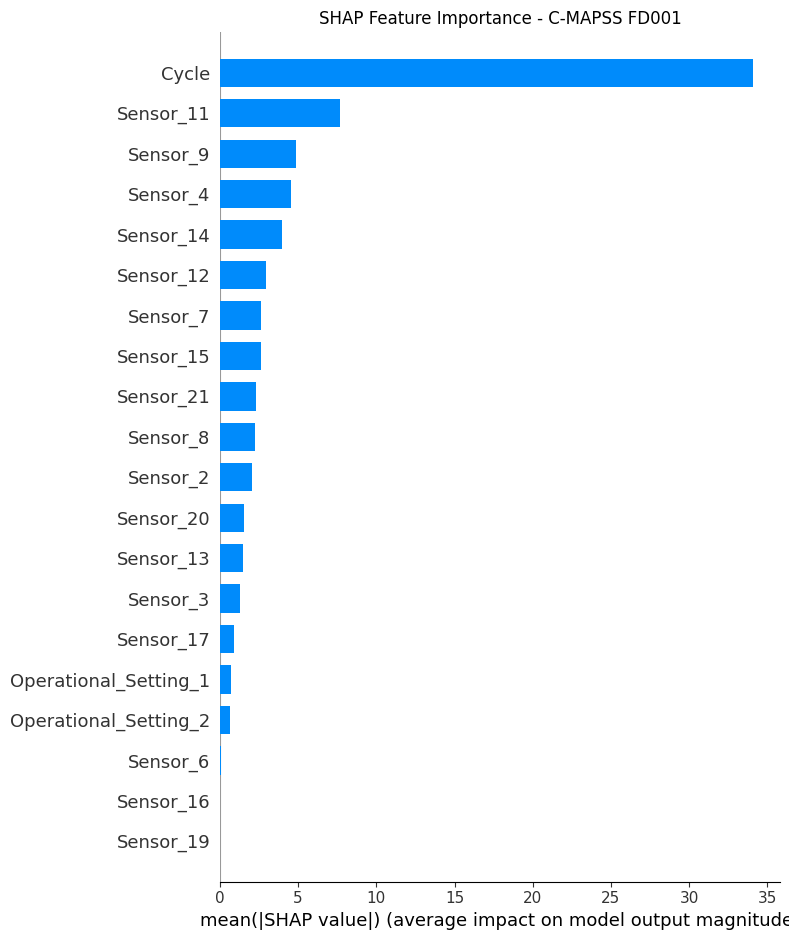

In [80]:
# ==========================================================
# 17. SHAP EXPLAINABILITY
# ==========================================================

try:
    import shap

    print("SHAP version:", shap.__version__)

    # Use a manageable sample for explanation
    shap_sample = X_validation.sample(
        min(1000, len(X_validation)),
        random_state=42
    )

    explainer = shap.TreeExplainer(xgb_model)
    shap_values = explainer.shap_values(shap_sample)

    plt.figure()
    shap.summary_plot(
        shap_values,
        shap_sample,
        show=False
    )
    plt.title("SHAP Summary - C-MAPSS FD001")
    plt.tight_layout()
    plt.show()

    plt.figure()
    shap.summary_plot(
        shap_values,
        shap_sample,
        plot_type="bar",
        show=False
    )
    plt.title("SHAP Feature Importance - C-MAPSS FD001")
    plt.tight_layout()
    plt.show()

except ImportError:
    print("SHAP is not installed.")
    print("Run: pip install shap")


In [81]:
# ==========================================================
# 18. STATISTICAL TREND LEARNING
# ==========================================================

# Select the sensor with the strongest absolute correlation with RUL.
sensor_columns = [
    column for column in train_df.columns
    if column.startswith("Sensor_")
]

sensor_correlations = (
    train_df[sensor_columns + ["RUL"]]
    .corr()["RUL"]
    .drop("RUL")
    .abs()
    .sort_values(ascending=False)
)

trend_sensor = sensor_correlations.index[0]

print("Sensor selected for trend learning:", trend_sensor)

trend_data = train_df[
    ["Unit", "Cycle", trend_sensor, "RUL"]
].copy()

trend_data["Rolling_Mean"] = (
    trend_data
    .groupby("Unit")[trend_sensor]
    .transform(
        lambda x: x.rolling(
            window=10,
            min_periods=3
        ).mean()
    )
)

trend_data["Rolling_Slope"] = (
    trend_data
    .groupby("Unit")[trend_sensor]
    .transform(
        lambda x: x.rolling(
            window=10,
            min_periods=3
        ).apply(
            lambda y: np.polyfit(
                np.arange(len(y)),
                y,
                1
            )[0],
            raw=True
        )
    )
)

trend_data["Trend_State"] = np.select(
    [
        trend_data["Rolling_Slope"] > 0.05,
        trend_data["Rolling_Slope"] < -0.05
    ],
    [
        "Increasing",
        "Decreasing"
    ],
    default="Stable"
)

print("\nTrend counts:")
print(trend_data["Trend_State"].value_counts())


Sensor selected for trend learning: Sensor_11

Trend counts:
Trend_State
Stable        20532
Increasing       52
Decreasing       47
Name: count, dtype: int64


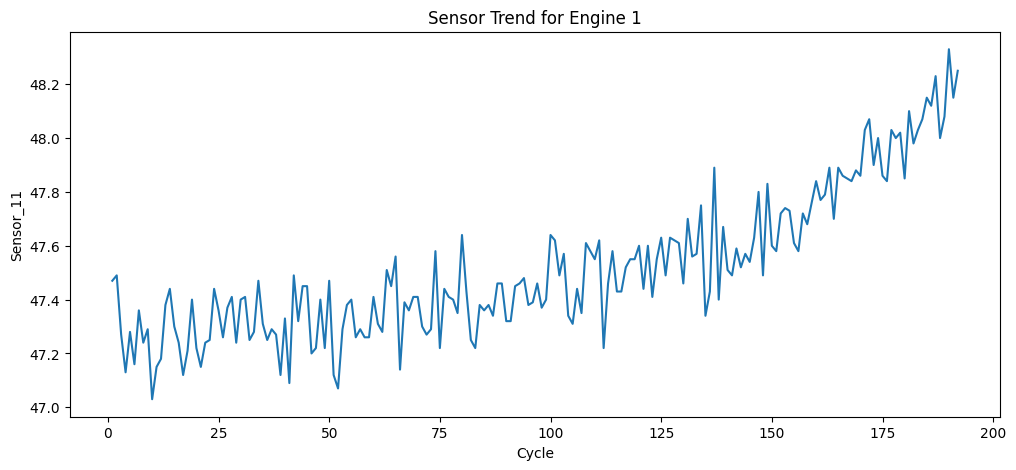

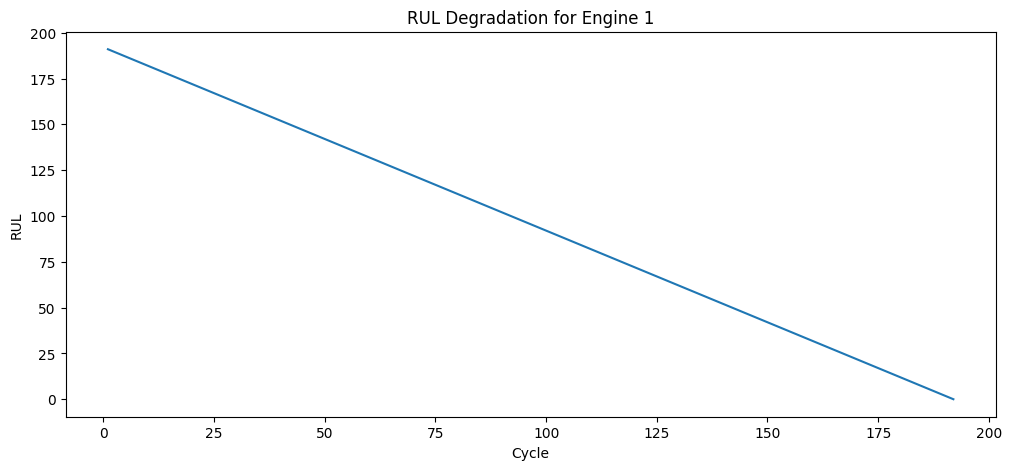

In [82]:
# ==========================================================
# 19. EXAMPLE ENGINE TREND
# ==========================================================

example_unit = train_df["Unit"].iloc[0]

example_trend = trend_data[
    trend_data["Unit"] == example_unit
]

plt.figure(figsize=(12, 5))
plt.plot(
    example_trend["Cycle"],
    example_trend[trend_sensor]
)

plt.xlabel("Cycle")
plt.ylabel(trend_sensor)
plt.title(
    "Sensor Trend for Engine " +
    str(example_unit)
)

plt.show()

plt.figure(figsize=(12, 5))
plt.plot(
    example_trend["Cycle"],
    example_trend["RUL"]
)

plt.xlabel("Cycle")
plt.ylabel("RUL")
plt.title(
    "RUL Degradation for Engine " +
    str(example_unit)
)

plt.show()


In [83]:
# ==========================================================
# 20. FINAL TEST SET PREPARATION
# ==========================================================

test_last = (
    test_df
    .sort_values(["Unit", "Cycle"])
    .groupby("Unit")
    .tail(1)
    .copy()
)

X_test = test_last[feature_columns]
y_test = test_last["RUL"]

print("Final test engines:", test_last["Unit"].nunique())
print(
    "Test rows used for final RUL evaluation:",
    len(test_last)
)

print(
    "\nMissing test RUL values:",
    y_test.isna().sum()
)

Final test engines: 100
Test rows used for final RUL evaluation: 100

Missing test RUL values: 0


In [84]:
# ==========================================================
# 21. FINAL TEST PREDICTION
# ==========================================================

test_pred = xgb_model.predict(X_test)

test_results = test_last[
    ["Unit", "Cycle", "RUL"]
].copy()

test_results["Predicted_RUL"] = test_pred

print(test_results.head(10))

print("\nMissing Actual RUL:",
      test_results["RUL"].isna().sum())

print("Missing Predicted RUL:",
      test_results["Predicted_RUL"].isna().sum())

      Unit  Cycle  RUL  Predicted_RUL
30       1     31  112     176.149277
79       2     49   98     149.383987
205      3    126   69      56.891605
311      4    106   82      81.240211
409      5     98   91     106.269188
514      6    105   93      88.533501
674      7    160   91     107.076752
840      8    166   95      70.620117
895      9     55  111     142.090393
1087    10    192   96     112.028763

Missing Actual RUL: 0
Missing Predicted RUL: 0


In [85]:
# ==========================================================
# 22. FINAL TEST PERFORMANCE
# ==========================================================

test_mae = mean_absolute_error(
    test_results["RUL"],
    test_results["Predicted_RUL"]
)

test_rmse = np.sqrt(
    mean_squared_error(
        test_results["RUL"],
        test_results["Predicted_RUL"]
    )
)

test_r2 = r2_score(
    test_results["RUL"],
    test_results["Predicted_RUL"]
)

print("=" * 70)
print("FINAL C-MAPSS FD001 TEST PERFORMANCE")
print("=" * 70)

print("MAE :", round(test_mae, 3))
print("RMSE:", round(test_rmse, 3))
print("R2  :", round(test_r2, 3))

FINAL C-MAPSS FD001 TEST PERFORMANCE
MAE : 19.706
RMSE: 27.253
R2  : 0.57


In [86]:
# ==========================================================
# 23. RATIONAL AGENT
# ==========================================================

# These are starting decision thresholds.
# They are intentionally kept simple for the first experiment.
#
# Lower RUL means greater maintenance urgency.

def rational_decision(predicted_rul):
    if predicted_rul > 40:
        return "Normal / Continue Operation"
    elif predicted_rul > 20:
        return "Monitor"
    elif predicted_rul > 10:
        return "Schedule Maintenance"
    else:
        return "Critical / Immediate Inspection"


test_results["Agent_Decision"] = (
    test_results["Predicted_RUL"]
    .apply(rational_decision)
)

print("Agent decision distribution:")
print(test_results["Agent_Decision"].value_counts())


Agent decision distribution:
Agent_Decision
Normal / Continue Operation        78
Monitor                            11
Schedule Maintenance                7
Critical / Immediate Inspection     4
Name: count, dtype: int64


In [87]:
# ==========================================================
# 24. TREND-AWARE RATIONAL AGENT
# ==========================================================

# Build trend information for the final test cycle of each engine.

test_trend = test_df[
    ["Unit", "Cycle", trend_sensor]
].copy()

test_trend["Rolling_Mean"] = (
    test_trend
    .groupby("Unit")[trend_sensor]
    .transform(
        lambda x: x.rolling(
            window=10,
            min_periods=3
        ).mean()
    )
)

test_trend["Rolling_Slope"] = (
    test_trend
    .groupby("Unit")[trend_sensor]
    .transform(
        lambda x: x.rolling(
            window=10,
            min_periods=3
        ).apply(
            lambda y: np.polyfit(
                np.arange(len(y)),
                y,
                1
            )[0],
            raw=True
        )
    )
)

test_trend["Trend_State"] = np.select(
    [
        test_trend["Rolling_Slope"] > 0.05,
        test_trend["Rolling_Slope"] < -0.05
    ],
    [
        "Increasing",
        "Decreasing"
    ],
    default="Stable"
)

test_trend_last = (
    test_trend
    .sort_values(["Unit", "Cycle"])
    .groupby("Unit")
    .tail(1)
)

test_results = test_results.merge(
    test_trend_last[
        ["Unit", "Trend_State", "Rolling_Slope"]
    ],
    on="Unit",
    how="left"
)

def trend_aware_decision(row):
    decision = row["Agent_Decision"]

    if (
        row["Trend_State"] == "Increasing"
        and decision == "Normal / Continue Operation"
    ):
        return "Monitor"

    elif (
        row["Trend_State"] == "Increasing"
        and decision == "Monitor"
    ):
        return "Schedule Maintenance"

    elif (
        row["Trend_State"] == "Increasing"
        and decision == "Schedule Maintenance"
    ):
        return "Critical / Immediate Inspection"

    return decision


test_results["Trend_Aware_Decision"] = (
    test_results.apply(
        trend_aware_decision,
        axis=1
    )
)

print("Trend-aware decision distribution:")
print(
    test_results["Trend_Aware_Decision"]
    .value_counts()
)


Trend-aware decision distribution:
Trend_Aware_Decision
Normal / Continue Operation        78
Monitor                            11
Schedule Maintenance                7
Critical / Immediate Inspection     4
Name: count, dtype: int64


In [88]:
# ==========================================================
# 25. POLICY FEEDBACK / SELF-EVOLVING EXPERIMENT
# ==========================================================

# The policy is evaluated on validation engines.
# Lower cumulative cost is preferred.
#
# This is a prototype self-evolving mechanism:
# it adapts the decision thresholds based on feedback,
# rather than changing the underlying physical system.

policy_list = {
    "Original": (40, 20, 10),
    "Conservative": (50, 30, 15),
    "Aggressive": (30, 15, 7)
}

def apply_policy(predicted_rul, thresholds):
    normal_limit, monitor_limit, maintenance_limit = thresholds

    if predicted_rul > normal_limit:
        return "Normal"
    elif predicted_rul > monitor_limit:
        return "Monitor"
    elif predicted_rul > maintenance_limit:
        return "Maintenance"
    else:
        return "Critical"


# Use final validation cycle for each validation engine.
validation_last = (
    validation_df
    .sort_values(["Unit", "Cycle"])
    .groupby("Unit")
    .tail(1)
    .copy()
)

validation_last["Predicted_RUL"] = (
    xgb_model.predict(
        validation_last[feature_columns]
    )
)

# Actual risk categories are defined from actual RUL.
def actual_category(rul):
    if rul > 40:
        return "Normal"
    elif rul > 20:
        return "Monitor"
    elif rul > 10:
        return "Maintenance"
    else:
        return "Critical"

validation_last["Actual_Category"] = (
    validation_last["RUL"]
    .apply(actual_category)
)

def policy_cost(row):
    actual = row["Actual_Category"]
    decision = row["Policy_Decision"]

    # Cost weights are illustrative and used consistently
    # for comparing candidate policies.
    if actual == "Critical" and decision in ["Normal", "Monitor"]:
        return 10

    if actual in ["Maintenance", "Critical"] and decision == "Normal":
        return 5

    if actual == "Normal" and decision in ["Maintenance", "Critical"]:
        return 1

    if actual == "Normal" and decision == "Monitor":
        return 0.1

    if actual == "Maintenance" and decision == "Monitor":
        return 0.5

    return 0


policy_results = []

for policy_name, thresholds in policy_list.items():

    temp = validation_last.copy()

    temp["Policy_Decision"] = (
        temp["Predicted_RUL"]
        .apply(
            lambda x: apply_policy(
                x,
                thresholds
            )
        )
    )

    total_cost = temp.apply(
        policy_cost,
        axis=1
    ).sum()

    policy_results.append({
        "Policy": policy_name,
        "Cost": total_cost,
        "Cost_per_Engine": total_cost / len(temp)
    })

policy_comparison = pd.DataFrame(policy_results)

print(policy_comparison)

best_policy = (
    policy_comparison
    .sort_values("Cost")
    .iloc[0]["Policy"]
)

print("\nSelected self-evolving policy:", best_policy)


         Policy  Cost  Cost_per_Engine
0      Original     0              0.0
1  Conservative     0              0.0
2    Aggressive     0              0.0

Selected self-evolving policy: Original


In [89]:
# ==========================================================
# 26. APPLY SELECTED ADAPTIVE POLICY TO TEST DATA
# ==========================================================

# Make sure the selected policy exists
print("=" * 70)
print("ADAPTIVE POLICY")
print("=" * 70)

print("Selected policy:", best_policy)

selected_thresholds = policy_list[best_policy]

print("Selected thresholds:", selected_thresholds)

# ----------------------------------------------------------
# APPLY POLICY
# ----------------------------------------------------------

test_results["Adaptive_Decision"] = (
    test_results["Predicted_RUL"]
    .apply(
        lambda x: apply_policy(
            x,
            selected_thresholds
        )
    )
)

# ----------------------------------------------------------
# CHECK
# ----------------------------------------------------------

print("\nAdaptive decision column created successfully.")

print("\nAdaptive decision distribution:")
print(
    test_results["Adaptive_Decision"]
    .value_counts()
)

print("\nFirst 10 adaptive decisions:")
print(
    test_results[
        [
            "Unit",
            "RUL",
            "Predicted_RUL",
            "Adaptive_Decision"
        ]
    ].head(10)
)

ADAPTIVE POLICY
Selected policy: Original
Selected thresholds: (40, 20, 10)

Adaptive decision column created successfully.

Adaptive decision distribution:
Adaptive_Decision
Normal         78
Monitor        11
Maintenance     7
Critical        4
Name: count, dtype: int64

First 10 adaptive decisions:
   Unit  RUL  Predicted_RUL Adaptive_Decision
0     1  112     176.149277            Normal
1     2   98     149.383987            Normal
2     3   69      56.891605            Normal
3     4   82      81.240211            Normal
4     5   91     106.269188            Normal
5     6   93      88.533501            Normal
6     7   91     107.076752            Normal
7     8   95      70.620117            Normal
8     9  111     142.090393            Normal
9    10   96     112.028763            Normal


In [90]:
# ==========================================================
# 27. FINAL ENGINE-LEVEL RESULTS
# ==========================================================

print("=" * 70)
print("FINAL C-MAPSS FD001 RESULTS")
print("=" * 70)

print("\nRUL PERFORMANCE")
print("MAE :", round(test_mae, 3))
print("RMSE:", round(test_rmse, 3))
print("R2  :", round(test_r2, 3))

print("\nRATIONAL AGENT")

print(
    test_results[
        [
            "Unit",
            "Cycle",
            "RUL",
            "Predicted_RUL",
            "Trend_State",
            "Agent_Decision",
            "Trend_Aware_Decision",
            "Adaptive_Decision"
        ]
    ].head(20)
)

print("\nDECISION COUNTS")

print(
    test_results[
        [
            "Agent_Decision",
            "Trend_Aware_Decision",
            "Adaptive_Decision"
        ]
    ].apply(pd.Series.value_counts)
)

FINAL C-MAPSS FD001 RESULTS

RUL PERFORMANCE
MAE : 19.706
RMSE: 27.253
R2  : 0.57

RATIONAL AGENT
    Unit  Cycle  RUL  Predicted_RUL Trend_State               Agent_Decision  \
0      1     31  112     176.149277      Stable  Normal / Continue Operation   
1      2     49   98     149.383987      Stable  Normal / Continue Operation   
2      3    126   69      56.891605      Stable  Normal / Continue Operation   
3      4    106   82      81.240211      Stable  Normal / Continue Operation   
4      5     98   91     106.269188      Stable  Normal / Continue Operation   
5      6    105   93      88.533501      Stable  Normal / Continue Operation   
6      7    160   91     107.076752      Stable  Normal / Continue Operation   
7      8    166   95      70.620117      Stable  Normal / Continue Operation   
8      9     55  111     142.090393      Stable  Normal / Continue Operation   
9     10    192   96     112.028763      Stable  Normal / Continue Operation   
10    11     83   97  

In [91]:
# ==========================================================
# 28. SAVE RESULTS
# ==========================================================

results_path = base_path + r"\CMAPSS_FD001_Agent_Results.csv"
policy_path = base_path + r"\CMAPSS_FD001_Policy_Comparison.csv"

test_results.to_csv(
    results_path,
    index=False
)

policy_comparison.to_csv(
    policy_path,
    index=False
)

print("Results saved successfully.")

print("\nResults file:")
print(results_path)

print("\nPolicy comparison file:")
print(policy_path)


Results saved successfully.

Results file:
C:\Users\kvspp\Downloads\aiml project\CMAPSSData\CMAPSS_FD001_Agent_Results.csv

Policy comparison file:
C:\Users\kvspp\Downloads\aiml project\CMAPSSData\CMAPSS_FD001_Policy_Comparison.csv


C-MAPSS FD001: TOP 2 FEATURES MODEL
Features: ['Cycle', 'Sensor_11']
Training samples: 16561
Validation samples: 4070

REGRESSION METRICS
MAE  : 25.1369 cycles
RMSE : 31.5644 cycles
R²   : 0.7688

CLASSIFICATION METRICS
Accuracy: 0.7978

Classification Report:

                     precision    recall  f1-score   support

     Low RUL (0-30)       0.89      0.68      0.77       620
Medium RUL (31-100)       0.73      0.66      0.69      1400
    High RUL (>100)       0.82      0.93      0.87      2050

           accuracy                           0.80      4070
          macro avg       0.81      0.76      0.78      4070
       weighted avg       0.80      0.80      0.79      4070


Confusion Matrix:
                     Low RUL (0-30)  Medium RUL (31-100)  High RUL (>100)
Low RUL (0-30)                  422                  198                0
Medium RUL (31-100)              51                  920              429
High RUL (>100)                   0                  145           

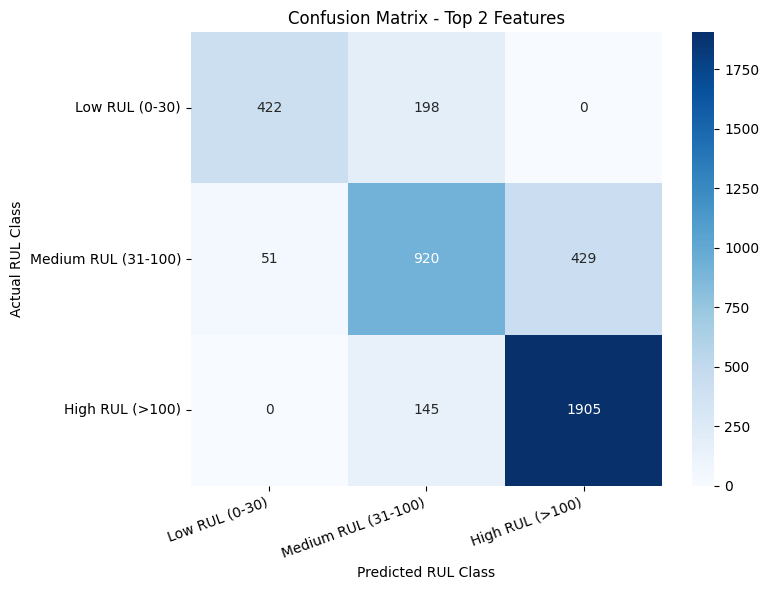

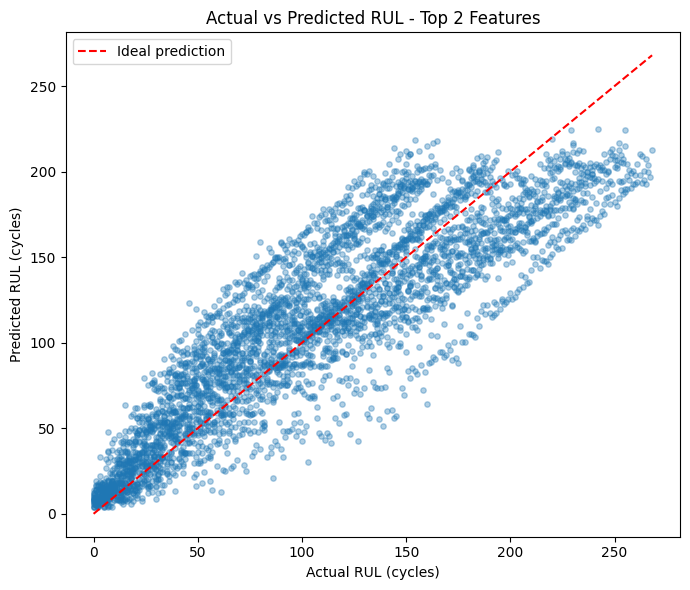

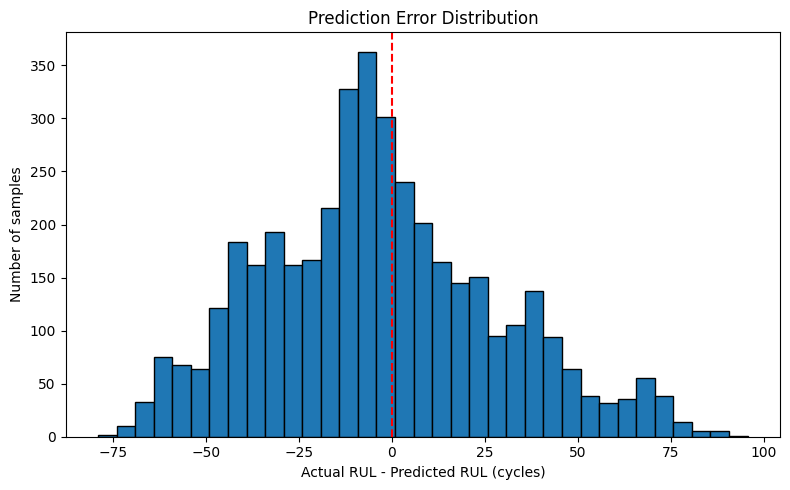

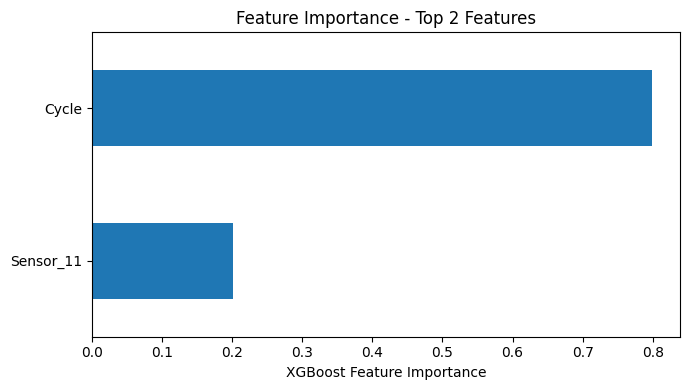


MODEL EXECUTION COMPLETED
Results and graphs saved in:
C:\Users\kvspp\Downloads\aiml project\CMAPSSData\FD001_Top2_Output_Graphs

Generated files:
 - 01_confusion_matrix.png
 - 02_actual_vs_predicted.png
 - 03_prediction_error.png
 - 04_feature_importance.png
 - FD001_Top2_Predictions.csv
 - classification_report.txt
 - confusion_matrix.csv
 - regression_metrics.csv


In [92]:

# ==========================================================
# 29. FAST MODEL USING TOP 2 SHAP FEATURES
# Features: Cycle and Sensor_11
# Dataset: C-MAPSS FD001
# ==========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    classification_report,
    accuracy_score
)

# ----------------------------------------------------------
# 1. PATHS
# ----------------------------------------------------------

base_path = r"C:\Users\kvspp\Downloads\aiml project\CMAPSSData"

plot_dir = os.path.join(base_path, "FD001_Top2_Output_Graphs")
os.makedirs(plot_dir, exist_ok=True)

TOP_FEATURES = ["Cycle", "Sensor_11"]

# ----------------------------------------------------------
# 2. CHECK DATAFRAMES
# ----------------------------------------------------------

if "validation_df" not in globals():
    raise NameError(
        "validation_df is missing. Run your data preparation "
        "and train-validation split cells first."
    )

if "model_train_df" in globals():
    train_source = model_train_df
elif "train_df" in globals():
    train_source = train_df
else:
    raise NameError(
        "Training dataframe missing. Run the training data cells first."
    )

required = TOP_FEATURES + ["RUL"]

missing_train = [c for c in required if c not in train_source.columns]
missing_valid = [c for c in required if c not in validation_df.columns]

if missing_train:
    raise ValueError(f"Missing training columns: {missing_train}")

if missing_valid:
    raise ValueError(f"Missing validation columns: {missing_valid}")

# ----------------------------------------------------------
# 3. PREPARE ONLY THE TOP TWO FEATURES
# ----------------------------------------------------------

train2 = (
    train_source[required]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

valid2 = (
    validation_df[required]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

if len(train2) == 0 or len(valid2) == 0:
    raise ValueError("Training or validation data is empty.")

X_train_top2 = train2[TOP_FEATURES]
y_train_top2 = train2["RUL"]

X_valid_top2 = valid2[TOP_FEATURES]
y_valid_top2 = valid2["RUL"]

print("=" * 60)
print("C-MAPSS FD001: TOP 2 FEATURES MODEL")
print("=" * 60)
print("Features:", TOP_FEATURES)
print("Training samples:", len(train2))
print("Validation samples:", len(valid2))

# ----------------------------------------------------------
# 4. TRAIN FAST XGBOOST REGRESSION MODEL
# ----------------------------------------------------------

top2_model = XGBRegressor(
    n_estimators=160,
    max_depth=3,
    learning_rate=0.08,
    subsample=0.85,
    colsample_bytree=1.0,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

top2_model.fit(X_train_top2, y_train_top2)

pred_top2 = np.clip(
    top2_model.predict(X_valid_top2),
    0,
    None
)

# ----------------------------------------------------------
# 5. REGRESSION METRICS
# ----------------------------------------------------------

mae = mean_absolute_error(y_valid_top2, pred_top2)
rmse = np.sqrt(mean_squared_error(y_valid_top2, pred_top2))
r2 = r2_score(y_valid_top2, pred_top2)

print("\nREGRESSION METRICS")
print(f"MAE  : {mae:.4f} cycles")
print(f"RMSE : {rmse:.4f} cycles")
print(f"R²   : {r2:.4f}")

metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Value": [mae, rmse, r2]
})
metrics_df.to_csv(
    os.path.join(plot_dir, "regression_metrics.csv"),
    index=False
)

# ----------------------------------------------------------
# 6. CONVERT RUL TO THREE CLASSES
# Low: 0-30, Medium: 31-100, High: >100
# ----------------------------------------------------------

class_labels = [
    "Low RUL (0-30)",
    "Medium RUL (31-100)",
    "High RUL (>100)"
]

def rul_band(values):
    return pd.cut(
        np.asarray(values),
        bins=[-np.inf, 30, 100, np.inf],
        labels=class_labels
    )

actual_class = rul_band(y_valid_top2)
predicted_class = rul_band(pred_top2)

# ----------------------------------------------------------
# 7. CONFUSION MATRIX AND CLASSIFICATION REPORT
# ----------------------------------------------------------

cm = confusion_matrix(
    actual_class,
    predicted_class,
    labels=class_labels
)

accuracy = accuracy_score(actual_class, predicted_class)

print("\nCLASSIFICATION METRICS")
print(f"Accuracy: {accuracy:.4f}")

report = classification_report(
    actual_class,
    predicted_class,
    labels=class_labels,
    target_names=class_labels,
    zero_division=0
)

print("\nClassification Report:\n")
print(report)

cm_df = pd.DataFrame(
    cm,
    index=class_labels,
    columns=class_labels
)

print("\nConfusion Matrix:")
print(cm_df)

cm_df.to_csv(
    os.path.join(plot_dir, "confusion_matrix.csv")
)

with open(
    os.path.join(plot_dir, "classification_report.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(f"Accuracy: {accuracy:.4f}\n\n")
    f.write(report)

# ----------------------------------------------------------
# 8. GRAPH 1: CONFUSION MATRIX
# ----------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix - Top 2 Features")
plt.xlabel("Predicted RUL Class")
plt.ylabel("Actual RUL Class")
plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(plot_dir, "01_confusion_matrix.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ----------------------------------------------------------
# 9. GRAPH 2: ACTUAL VS PREDICTED RUL
# ----------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.scatter(
    y_valid_top2,
    pred_top2,
    alpha=0.35,
    s=15
)

low = min(float(y_valid_top2.min()), float(pred_top2.min()))
high = max(float(y_valid_top2.max()), float(pred_top2.max()))

plt.plot(
    [low, high],
    [low, high],
    "r--",
    label="Ideal prediction"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Actual vs Predicted RUL - Top 2 Features")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(plot_dir, "02_actual_vs_predicted.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ----------------------------------------------------------
# 10. GRAPH 3: PREDICTION ERROR DISTRIBUTION
# ----------------------------------------------------------

residuals = np.asarray(y_valid_top2) - pred_top2

plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=35,
    edgecolor="black"
)

plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Actual RUL - Predicted RUL (cycles)")
plt.ylabel("Number of samples")
plt.title("Prediction Error Distribution")
plt.tight_layout()

plt.savefig(
    os.path.join(plot_dir, "03_prediction_error.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ----------------------------------------------------------
# 11. GRAPH 4: FEATURE IMPORTANCE
# ----------------------------------------------------------

importance = pd.Series(
    top2_model.feature_importances_,
    index=TOP_FEATURES
).sort_values()

plt.figure(figsize=(7, 4))

importance.plot(kind="barh")

plt.xlabel("XGBoost Feature Importance")
plt.title("Feature Importance - Top 2 Features")
plt.tight_layout()

plt.savefig(
    os.path.join(plot_dir, "04_feature_importance.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ----------------------------------------------------------
# 12. SAVE PREDICTIONS
# ----------------------------------------------------------

results = pd.DataFrame({
    "Actual_RUL": np.asarray(y_valid_top2),
    "Predicted_RUL": pred_top2,
    "Actual_RUL_Class": actual_class.astype(str),
    "Predicted_RUL_Class": predicted_class.astype(str)
})

results.to_csv(
    os.path.join(plot_dir, "FD001_Top2_Predictions.csv"),
    index=False
)

print("\n" + "=" * 60)
print("MODEL EXECUTION COMPLETED")
print("=" * 60)
print("Results and graphs saved in:")
print(plot_dir)
print("\nGenerated files:")
for filename in sorted(os.listdir(plot_dir)):
    print(" -", filename)
